## Импорты и настройки

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost
import lightgbm as lgb

from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score, KFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import mean_absolute_error, r2_score
from xgboost import XGBRegressor
from catboost import CatBoostRegressor


warnings.filterwarnings('ignore')
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

plt.rcParams.update({
    'figure.figsize': (10, 5),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
    'axes.titlesize': 13,
})

print(f'pandas {pd.__version__} | xgboost {xgboost.__version__} | sklearn ok')

pandas 3.0.0 | xgboost 3.4.1 | sklearn ok


### CONFIG

In [2]:
PREMIUM_BRANDS = {
    'PORSCHE', 'MERCEDES-BENZ', 'BMW', 'LEXUS', 'AUDI', 'TESLA', 'JAGUAR',
    'LAND ROVER', 'INFINITI', 'CADILLAC', 'MASERATI', 'BENTLEY', 'FERRARI',
    'LAMBORGHINI', 'ROLLS-ROYCE', 'ASTON MARTIN', 'MCLAREN',
}

CONFIG = {
    'RANDOM_STATE': 42,       
    'TEST_SIZE': 0.2,         
    'CV_FOLDS': 3,            

    'LOG_TARGET': True,
    
    'USE_MODEL_FEATURE': True,  
    'TE_FOLDS': 5,              
    'TE_SMOOTHING': 20,         

    
    'SEARCH_ITER_MAIN': 25,   
    'SEARCH_ITER_FINAL': 60,  
    'SEARCH_N_JOBS': 4,       

    

    'REF_YEAR': 2021,         
}


for _k, _v in CONFIG.items():
    globals()[_k] = _v

COLORS = {'baseline': '#95A5A6', 'linear': '#2E86AB', 'xgb': '#E67E22', 'final': '#C0392B'}

In [3]:
import kagglehub

path = kagglehub.dataset_download('deepcontractor/car-price-prediction-challenge')
print('Path to dataset files:', path)

Path to dataset files: /home/ydlawq/.cache/kagglehub/datasets/deepcontractor/car-price-prediction-challenge/versions/1


In [4]:
df_raw = pd.read_csv(os.path.join(path, 'car_price_prediction.csv'))
print(f'Размер: {df_raw.shape[0]} строк × {df_raw.shape[1]} колонок')
df_raw.head()

Размер: 19237 строк × 18 колонок


,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.00,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.00,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.00,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.00,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.00,Automatic,Front,04-May,Left wheel,Silver,4


In [5]:
DOORS_MAP = {'02-Mar': 2, '04-May': 4, '>5': 5}


# Нормализация 
def normalize_model(s: pd.Series) -> pd.Series:
    s = s.str.upper().str.strip()
    s = s.str.replace(r'\s+', ' ', regex=True)
    s = s.str.replace(r'[^A-Z0-9 ]', '', regex=True)
    return s

# Перевод текстовых колонок в число
def clean_formats(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    
    df['Levy'] = pd.to_numeric(df['Levy'].replace('-', np.nan), errors='coerce')

    
    df['Mileage_km'] = pd.to_numeric(
        df['Mileage'].str.replace(' km', '', regex=False), errors='coerce')

    
    df['Engine_volume'] = pd.to_numeric(
        df['Engine volume'].str.replace('Turbo', '', regex=False).str.strip(), errors='coerce')

    
    df['Doors_num'] = df['Doors'].map(DOORS_MAP)

    
    df['Model'] = normalize_model(df['Model'])

    return df


df = clean_formats(df_raw)
print(f"Уникальных моделей: {df_raw['Model'].nunique()} -> {df['Model'].nunique()} после нормализации")
df[['Levy', 'Mileage_km', 'Engine_volume', 'Doors_num']].head()

Уникальных моделей: 1590 -> 1505 после нормализации


,Levy,Mileage_km,Engine_volume,Doors_num
0,"1,399.00",186005,3.50,4
1,"1,018.00",192000,3.00,4
2,NaN,200000,1.30,4
3,862.00,168966,2.50,4
4,446.00,91901,1.30,4


## EDA 



,count,mean,std,min,25%,50%,75%,max
Price,"19,237.00","18,555.93","190,581.27",1.00,"5,331.00","13,172.00","22,075.00","26,307,500.00"
Levy,"13,418.00",906.84,461.87,87.00,640.00,781.00,"1,058.00","11,714.00"
Prod. year,"19,237.00","2,010.91",5.67,"1,939.00","2,009.00","2,012.00","2,015.00","2,020.00"
Mileage_km,"19,237.00","1,532,235.69","48,403,869.38",0.00,"70,139.00","126,000.00","188,888.00","2,147,483,647.00"
Engine_volume,"19,237.00",2.31,0.88,0.00,1.80,2.00,2.50,20.00
Cylinders,"19,237.00",4.58,1.20,1.00,4.00,4.00,4.00,16.00
Airbags,"19,237.00",6.58,4.32,0.00,4.00,6.00,12.00,16.00
Doors_num,"19,237.00",3.93,0.40,2.00,4.00,4.00,4.00,5.00


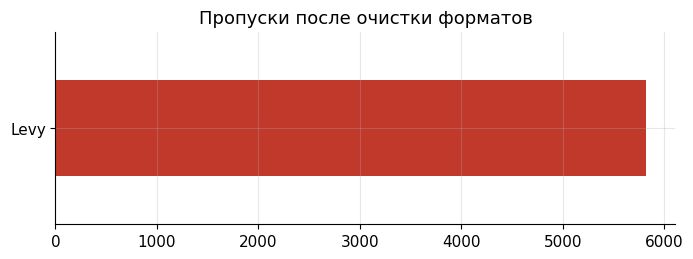

,NaN,"""-"" в сырых данных"
Levy,5819,"5,819.00"


In [6]:
num_overview = ['Price', 'Levy', 'Prod. year', 'Mileage_km', 'Engine_volume', 'Cylinders', 'Airbags', 'Doors_num']
display(df[num_overview].describe().T)

# Пропуски
missing = pd.DataFrame({
    'NaN': df.isna().sum(),
    '\"-\" в сырых данных': df_raw.isin(['-']).sum(),
}).query('`NaN` > 0 or `\"-\" в сырых данных` > 0')

fig, ax = plt.subplots(figsize=(8, 2.5))
missing['NaN'].plot.barh(ax=ax, color='#C0392B')
ax.set_title('Пропуски после очистки форматов')
plt.show()
missing

### Распределение `Price`

Цена распределена крайне неравномерно: хвост тянется до $26M. Поэтому в моделях используем `log1p(Price)` — это можно переключить флагом `LOG_TARGET` в конфиге.

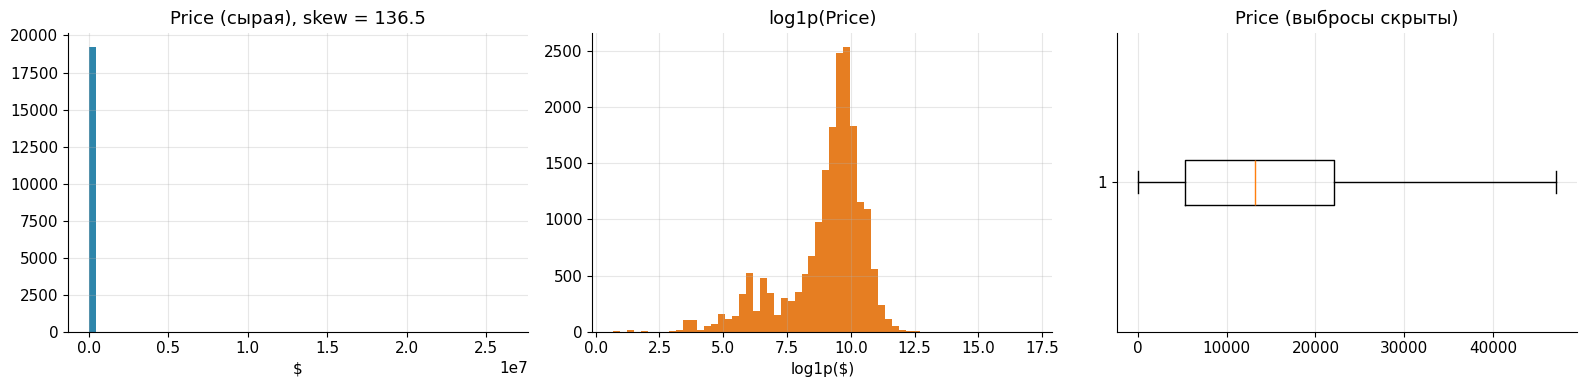

Минимум: $1 | Максимум: $26,307,500
Цена < $500:   1663 строк
Цена > $500k:  3 строк


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df['Price'], bins=60, color=COLORS['linear'])
axes[0].set_title(f'Price (сырая), skew = {df["Price"].skew():.1f}')
axes[0].set_xlabel('$')

axes[1].hist(np.log1p(df['Price']), bins=60, color=COLORS['xgb'])
axes[1].set_title('log1p(Price)')
axes[1].set_xlabel('log1p($)')

axes[2].boxplot(df['Price'], vert=False, showfliers=False)
axes[2].set_title('Price (выбросы скрыты)')

plt.tight_layout()
plt.show()

print(f"Минимум: ${df['Price'].min():,} | Максимум: ${df['Price'].max():,}")
print(f"Цена < $500:   {(df['Price'] < 500).sum()} строк")
print(f"Цена > $500k:  {(df['Price'] > 500_000).sum()} строк")

### Числовые признаки

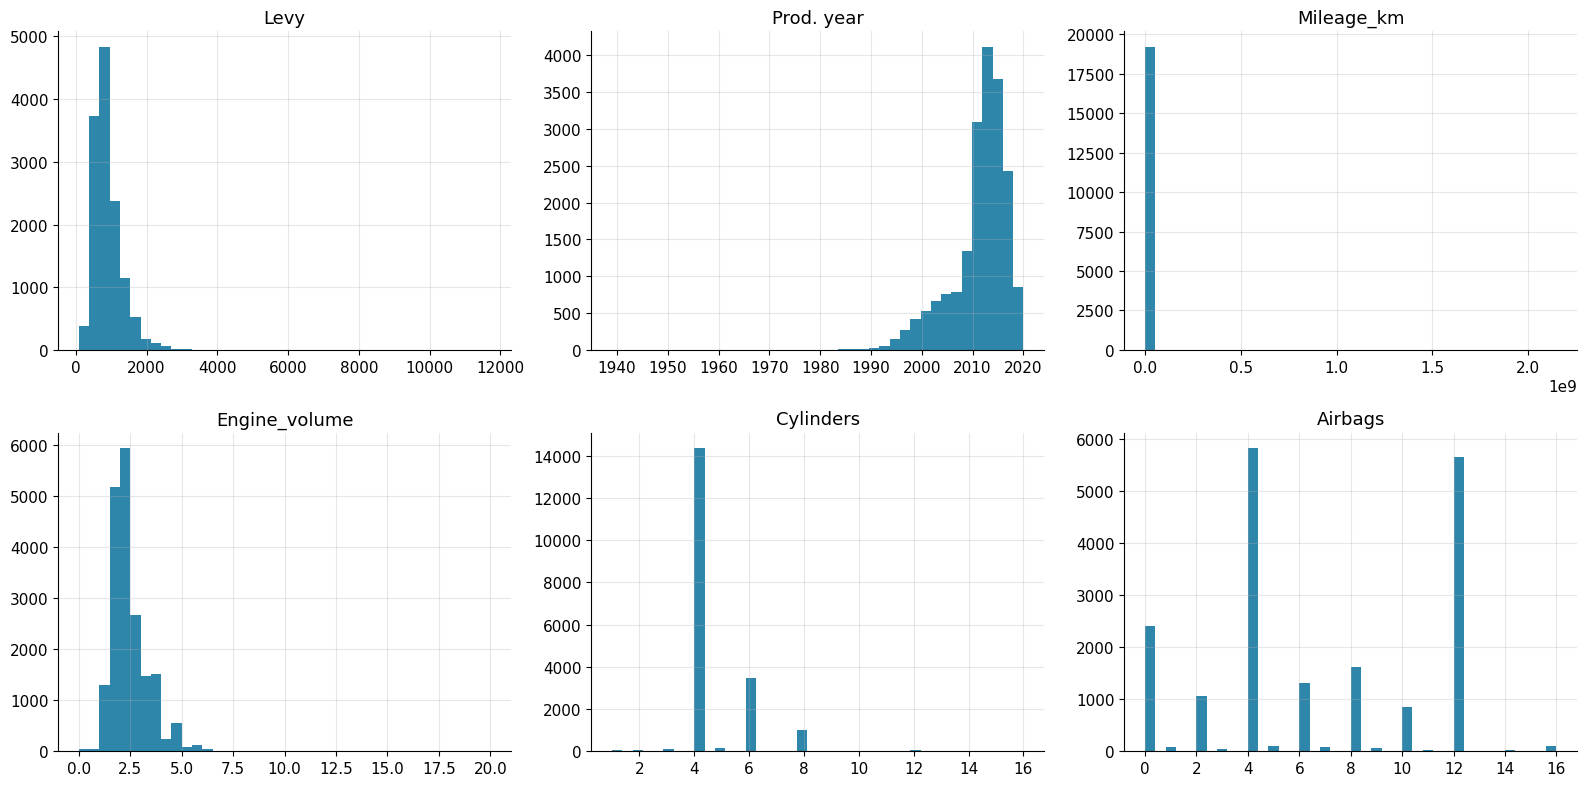

In [8]:
num_cols = ['Levy', 'Prod. year', 'Mileage_km', 'Engine_volume', 'Cylinders', 'Airbags']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, num_cols):
    ax.hist(df[col].dropna(), bins=40, color=COLORS['linear'])
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Категориальные признаки

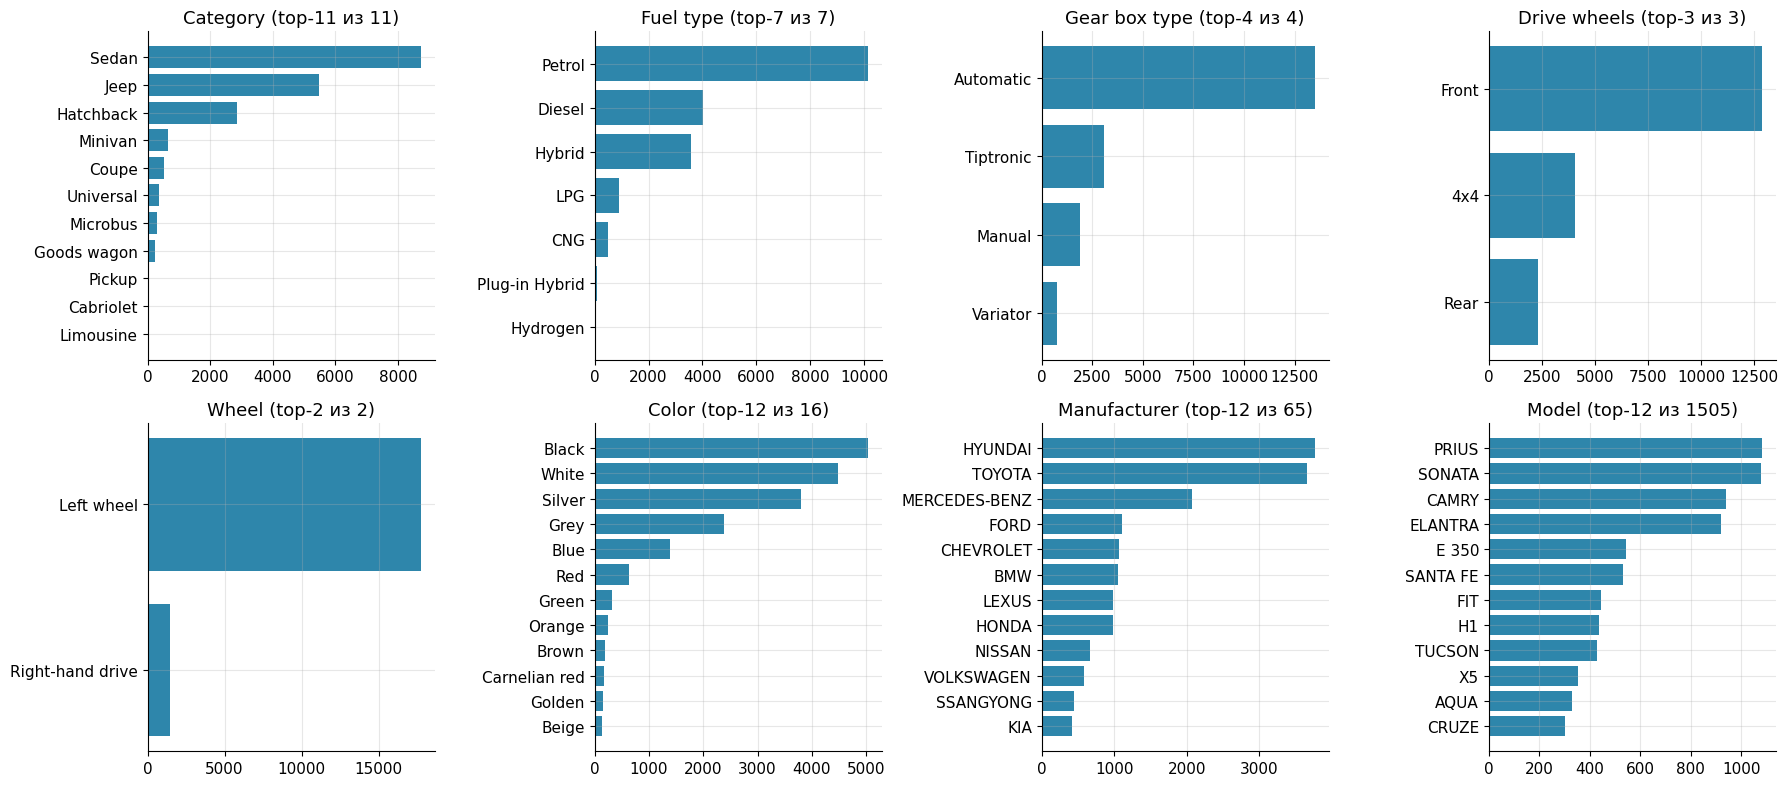

In [9]:
cat_cols = ['Category', 'Fuel type', 'Gear box type', 'Drive wheels', 'Wheel', 'Color', 'Manufacturer', 'Model']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, cat_cols):
    vc = df[col].value_counts().head(12)
    ax.barh(vc.index[::-1], vc.values[::-1], color=COLORS['linear'])
    ax.set_title(f'{col} (top-{len(vc)} из {df[col].nunique()})')
plt.tight_layout()
plt.show()

### Связь признаков с ценой

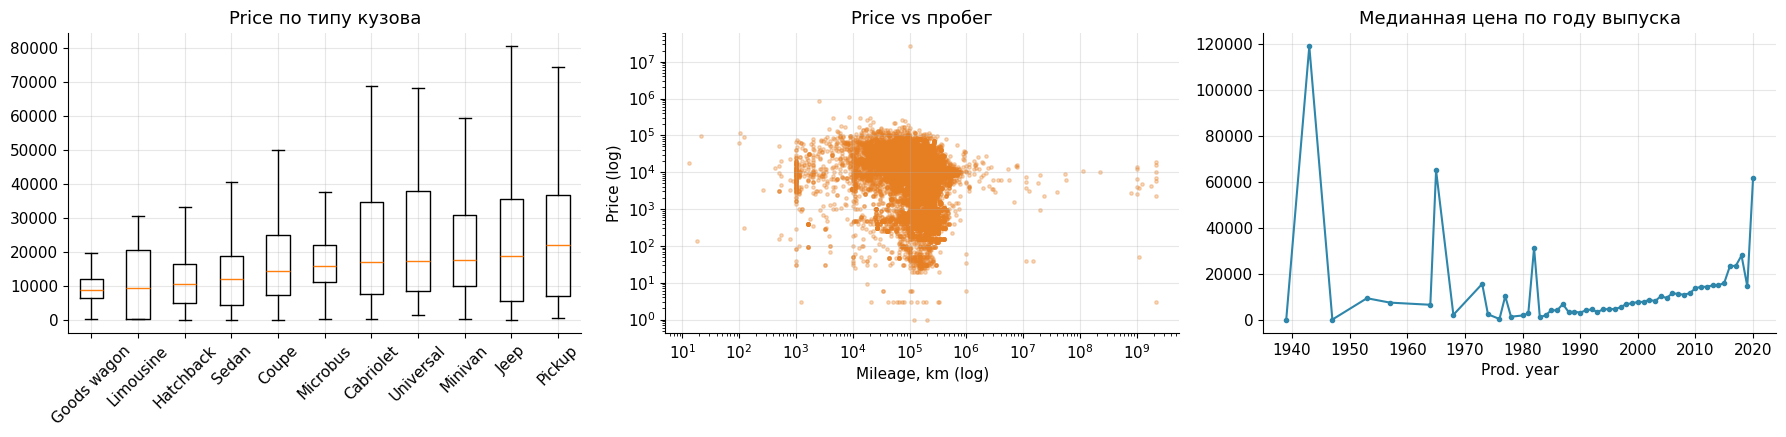

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1) Цена по типу кузова
order = df.groupby('Category')['Price'].median().sort_values().index
axes[0].boxplot([df.loc[df['Category'] == c, 'Price'] for c in order],
                tick_labels=order, showfliers=False)
axes[0].set_title('Price по типу кузова')
axes[0].tick_params(axis='x', rotation=45)

# 2) Цена vs пробег (в log)
axes[1].scatter(df['Mileage_km'], df['Price'], s=6, alpha=0.3, color=COLORS['xgb'])
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Mileage, km (log)')
axes[1].set_ylabel('Price (log)')
axes[1].set_title('Price vs пробег')

# 3) Медианная цена по году выпуска
med_by_year = df.groupby('Prod. year')['Price'].median()
axes[2].plot(med_by_year.index, med_by_year.values, marker='o', ms=3, color=COLORS['linear'])
axes[2].set_title('Медианная цена по году выпуска')
axes[2].set_xlabel('Prod. year')

plt.tight_layout()
plt.show()

### Корреляции числовых признаков

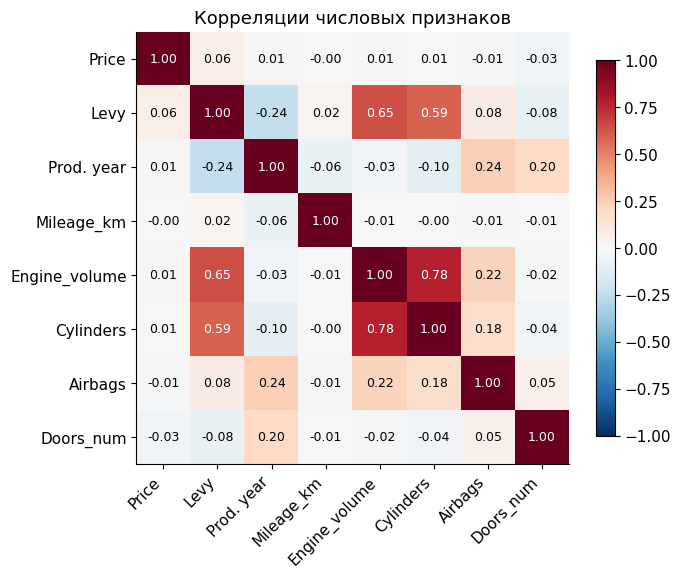

In [11]:
corr = df[num_overview].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9,
                color='white' if abs(v) > 0.5 else 'black')
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Корреляции числовых признаков')
plt.tight_layout()
plt.show()

**Выводы по EDA:**
- `Price` — сильный правый хвост (skew ≈ 14), есть выбросы от $1 до $26M → обучаем модели на `log1p`, а нереалистичные цены убираем из датасета
- `Levy` — ~30% скрытых пропусков (`'-'`): сам по себе он слабый, но флаг «Levy не указан» может быть полезным сигналом;
- С ценой сильнее всего связан **год выпуска** (новее — дороже), пробег и тип кузова тоже информативны;
- `Model` — высококардинальный признак: OHE его раздувает, поэтому применим **target encoding**;
- Объявления дублируются  — это шум,уберём агрегацией по медиане.

##  Feature engineering <a id='4'></a>

Базовые признаки (строковые колонки уже не нужны — числовые версии сделали в разделе 2).

In [12]:
def add_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # Турбомотор из исходной строки
    df['Turbo'] = df['Engine volume'].str.contains('Turbo').astype(int)

    # Возраст авто
    df['Car_Age'] = (REF_YEAR - df['Prod. year']).clip(lower=0)

    # Сырые строковые версии не нужны
    df = df.drop(columns=['ID', 'Mileage', 'Engine volume', 'Doors'])

    return df


# Очистка выбросов
df_fe = add_features(df)

mileage_bad = int((df_fe['Mileage_km'] > 600_000).sum())
df_fe['Mileage_km'] = df_fe['Mileage_km'].clip(upper=600_000)


engine_bad = int(((df_fe['Engine_volume'] > 10) | (df_fe['Engine_volume'] == 0)).sum())
df_fe.loc[df_fe['Engine_volume'] > 10, 'Engine_volume'] = np.nan
df_fe.loc[df_fe['Engine_volume'] == 0, 'Engine_volume'] = np.nan

q_low = df_fe['Price'].quantile(0.02)
q_high = df_fe['Price'].quantile(0.995)
n_before = len(df_fe)
df_fe = df_fe[df_fe['Price'].between(q_low, q_high)]
print(f'Убрано нереалистичных цен (вне [{q_low:,}, {q_high:,}]): {n_before - len(df_fe)} строк')

print(f'После feature engineering: {df_fe.shape[0]} строк × {df_fe.shape[1]} колонок')
df_fe.head(3)

Убрано нереалистичных цен (вне [110.0, 103,491.0]): 476 строк
После feature engineering: 18761 строк × 19 колонок


,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Cylinders,Gear box type,Drive wheels,Wheel,Color,Airbags,Mileage_km,Engine_volume,Doors_num,Turbo,Car_Age
0,13328,"1,399.00",LEXUS,RX 450,2010,Jeep,Yes,Hybrid,6.00,Automatic,4x4,Left wheel,Silver,12,186005,3.50,4,0,11
1,16621,"1,018.00",CHEVROLET,EQUINOX,2011,Jeep,No,Petrol,6.00,Tiptronic,4x4,Left wheel,Black,8,192000,3.00,4,0,10
2,8467,NaN,HONDA,FIT,2006,Hatchback,No,Petrol,4.00,Variator,Front,Right-hand drive,Black,2,200000,1.30,4,0,15


##  Модели <a id='5'></a>

1. **Бейзлайн** — всегда предсказывает медиану: нижняя планка для сравнения;
2. **Linear Regression** — простая интерпретируемая модель;
3. **XGBoost** — с подбором гиперпараметров (`RandomizedSearchCV`, скоринг — `neg MAE`).

Метрика везде — **MAE на test в исходных долларах** (при `LOG_TARGET=True` модели учатся на `log1p(Price)`, предсказания возвращаются через `expm1`).


### Split и препроцессинг

In [13]:
TARGET = 'Price'

X = df_fe.drop(columns=[TARGET])
y = df_fe[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=42)
print(f'train: {X_train.shape} | test: {X_test.shape}')

BASE_NUM = ['Levy', 'Prod. year', 'Car_Age', 'Mileage_km', 'Engine_volume',
            'Cylinders', 'Airbags', 'Doors_num', 'Turbo']
EXTRA_NUM = ['Levy_missing', 'Mileage_per_year', 'Engine_per_cyl', 'Model_freq', 'Is_premium']


def make_preprocessor(te_pairs=(), extra_feats=False):
    te_out = [c + '_te' for c, _ in te_pairs]
    te_src = [c for c, _ in te_pairs]
    num = list(BASE_NUM) + (EXTRA_NUM if extra_feats else []) + te_out
    cat = [c for c in X_train.columns if c not in num and c not in te_src]

    te_step = TargetEncoder(
        target_type='continuous',
        smooth='auto',
        cv=5,
        random_state=42,
    ) if te_pairs else 'passthrough'

    ct =  ColumnTransformer([
        ('num', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
        ]), num),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=True)),
        ]), cat),
    ])

    return Pipeline([
        ('te', te_step),
        ('ct', ct),
    ])


def wrap_target(regressor):
    if LOG_TARGET:
        return TransformedTargetRegressor(
            regressor=regressor, func=np.log1p, inverse_func=np.expm1)
    return regressor

train: (15008, 18) | test: (3753, 18)


### Обучение и сравнение

In [14]:
results = []   
fitted = {}    


def evaluate(name, pipe, key, cv=True):
    t0 = time.time()
    pipe.fit(X_train, y_train)
    fit_time = time.time() - t0

    pred = pipe.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)

    cv_mae = np.nan
    if cv:
        cv_mae = -cross_val_score(
            pipe, X_train, y_train,
            cv=KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE),
            scoring='neg_mean_absolute_error', n_jobs=-1,
        ).mean()

    results.append({'Модель': name, 'MAE (test)': mae, 'MAE (CV, train)': cv_mae,
                    'R² (test)': r2, 'Время, с': fit_time})
    fitted[key] = pipe
    print(f'{name:<25} MAE (test) = {mae:>10,.0f} $   R² = {r2:.3f}')


evaluate('Бейзлайн (медиана)',
         Pipeline([('model', wrap_target(DummyRegressor(strategy='median')))]),
         key='baseline', cv=False)

Бейзлайн (медиана)        MAE (test) =     11,225 $   R² = -0.066


In [15]:
lr_pipe = Pipeline([
    ('prep', make_preprocessor()),
    ('model', wrap_target(LinearRegression())),
])
evaluate('Linear Regression', lr_pipe, key='linear')

Linear Regression         MAE (test) =      9,406 $   R² = -0.070


In [16]:
xgb_pipe = Pipeline([
    ('prep', make_preprocessor()),
    ('model', wrap_target(XGBRegressor(
        tree_method='hist', random_state=RANDOM_STATE, n_jobs=4))),
])
evaluate('XGBoost (default)', xgb_pipe, key='xgb_default', cv=False)

XGBoost (default)         MAE (test) =      5,411 $   R² = 0.577


### Подбор гиперпараметров XGBoost (на OHE-признаках)

In [17]:
prefix = 'model__regressor__' 

param_dists = {f'{prefix}{name}': grid for name, grid in {
    'n_estimators':     [300, 500, 800, 1200],
    'learning_rate':    [0.02, 0.05, 0.08, 0.1],
    'max_depth':        [4, 6, 8, 10],
    'min_child_weight': [1, 3, 5, 10],
    'subsample':        [0.6, 0.8, 1.0],
    'colsample_bytree': [0.4, 0.6, 0.8, 1.0],
    'reg_lambda':       [0.5, 1, 5, 10],
}.items()}

search = RandomizedSearchCV(
    xgb_pipe, param_dists,
    n_iter=SEARCH_ITER_MAIN,
    scoring='neg_mean_absolute_error',
    cv=KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=SEARCH_N_JOBS, random_state=RANDOM_STATE, verbose=1,
)
search.fit(X_train, y_train)

print(f'Лучший MAE по CV: {-search.best_score_:,.0f} $')
print('Лучшие параметры:')
for k, v in search.best_params_.items():
    print(f'  {k.replace(prefix, "")}: {v}')

Fitting 3 folds for each of 25 candidates, totalling 75 fits
Лучший MAE по CV: 4,506 $
Лучшие параметры:
  subsample: 0.8
  reg_lambda: 5
  n_estimators: 300
  min_child_weight: 1
  max_depth: 10
  learning_rate: 0.08
  colsample_bytree: 0.6


In [18]:
pred = search.best_estimator_.predict(X_test)
results.append({
    'Модель': 'XGBoost (tuned)',
    'MAE (test)': mean_absolute_error(y_test, pred),
    'MAE (CV, train)': -search.best_score_,
    'R² (test)': r2_score(y_test, pred),
    'Время, с': np.nan,
})
print(f'XGBoost (tuned)           MAE (test) = {results[-1]["MAE (test)"]:>10,.0f} $')

XGBoost (tuned)           MAE (test) =      4,484 $


### Итоговое сравнение

,Модель,MAE (test),"MAE (CV, train)",R² (test),"Время, с"
0,XGBoost (tuned),"4,484","4,506",0.717,—
1,XGBoost (default),"5,411",—,0.577,0.2
2,Linear Regression,"9,406","9,218",-0.070,0.6
3,Бейзлайн (медиана),"11,225",—,-0.066,0.0


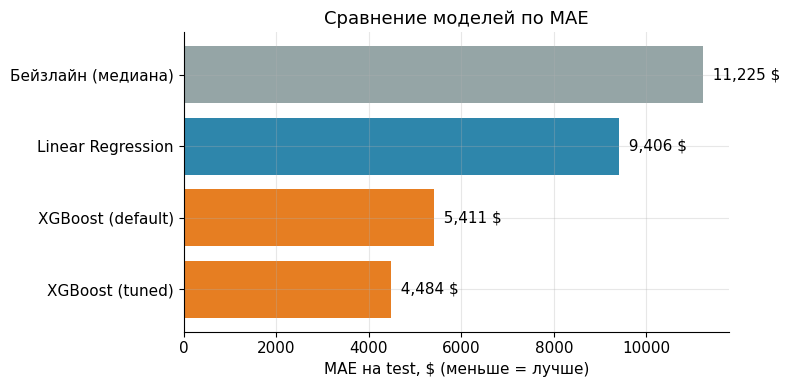

In [19]:
results_df = (
    pd.DataFrame(results)
    .sort_values('MAE (test)')
    .reset_index(drop=True)
)

display(
    results_df
    .style
    .format({'MAE (test)': '{:,.0f}', 'MAE (CV, train)': '{:,.0f}',
             'R² (test)': '{:.3f}', 'Время, с': '{:.1f}'}, na_rep='—')
    .background_gradient(subset=['MAE (test)'], cmap='RdYlGn_r')
)

fig, ax = plt.subplots(figsize=(8, 4))
plot_df = results_df.sort_values('MAE (test)')
colors = [COLORS['baseline'] if 'Бейзлайн' in m else
          (COLORS['linear'] if 'Linear' in m else COLORS['xgb'])
          for m in plot_df['Модель']]
ax.barh(plot_df['Модель'], plot_df['MAE (test)'], color=colors)
ax.set_xlabel('MAE на test, $ (меньше = лучше)')
ax.set_title('Cравнение моделей по MAE')
for i, (_, row) in enumerate(plot_df.iterrows()):
    ax.text(row['MAE (test)'], i, f"  {row['MAE (test)']:,.0f} $", va='center')
plt.tight_layout()
plt.show()